# 04 · Segmentación con una U-Net

Segmentar es clasificar cada pixel. Comparamos un umbral fijo de brillo con una U-Net pequeña sobre
«mazorcas» sintéticas con sombras, y medimos con Dice e IoU.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
import torch
from applied_cv.masks import dice, mask_iou
from applied_cv.unet import UNet
from torch import nn


def sample(size=32):
    yy, xx = np.mgrid[0:size, 0:size] / size
    cy, cx = rng.uniform(0.35, 0.65, 2)
    mask = ((xx - cx) / rng.uniform(0.15, 0.25)) ** 2 + (
        (yy - cy) / rng.uniform(0.25, 0.35)
    ) ** 2 < 1
    light = 0.4 + 0.6 * xx  # iluminación lateral
    img = np.where(mask, 0.7, 0.45) * light + rng.normal(0, 0.06, (size, size))
    return img.astype(np.float32), mask


data = [sample() for _ in range(400)]
X = torch.tensor(np.stack([d[0] for d in data]))[:, None]
Y = torch.tensor(np.stack([d[1] for d in data])).long()
Xtr, Ytr, Xte, Yte = X[:300], Y[:300], X[300:], Y[300:]
print(Xtr.shape, Xte.shape)

torch.Size([300, 1, 32, 32]) torch.Size([100, 1, 32, 32])


In [2]:
thr = float(Xtr.mean())
base_dice = np.mean([dice(x[0].numpy() > thr, y.numpy()) for x, y in zip(Xte, Yte, strict=True)])
print(f"umbral fijo de brillo: Dice = {base_dice:.3f}")

umbral fijo de brillo: Dice = 0.528


In [3]:
torch.manual_seed(42)
net = UNet(1, 2, base=8)
opt = torch.optim.Adam(net.parameters(), lr=3e-3)
for _ in range(150):
    idx = torch.randint(0, len(Xtr), (32,))
    opt.zero_grad()
    loss = nn.functional.cross_entropy(net(Xtr[idx]), Ytr[idx])
    loss.backward()
    opt.step()
net.eval()
with torch.no_grad():
    pred = net(Xte).argmax(1).numpy()
scores = [(dice(p, y.numpy()), mask_iou(p, y.numpy())) for p, y in zip(pred, Yte, strict=True)]
dice_mean, iou_mean = np.mean(scores, axis=0)
print(f"U-Net: Dice = {dice_mean:.3f}  IoU = {iou_mean:.3f}")

U-Net: Dice = 0.980  IoU = 0.961


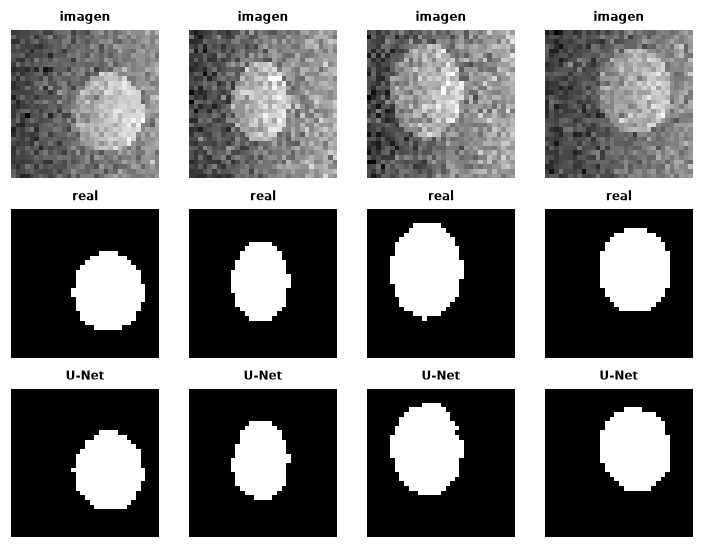

In [4]:
fig, ax = plt.subplots(3, 4, figsize=(8, 6))
for j in range(4):
    for i, (im, t) in enumerate(((Xte[j, 0], "imagen"), (Yte[j], "real"), (pred[j], "U-Net"))):
        ax[i, j].imshow(im, cmap="gray")
        ax[i, j].axis("off")
        ax[i, j].set_title(t, fontsize=8)

**Lectura.** La iluminación lateral hace que el umbral global confunda el fondo iluminado
con la mazorca a la sombra; la U-Net usa contexto (forma y bordes) y no solo el brillo del pixel.
Dice siempre es ≥ IoU (IoU = Dice / (2 − Dice)).